#Parcial 2- Estadística y Exploración de Datos
 Pellegrini Lucía DNI:33107143



##Problema 1: Regresión Lineal Simple
 Objetivo: Analizar si la participación en clase es un buen predictor del rendimiento académico final.
  -Intrucciones:
  1. Ajustá un modelo de regresión lineal simple con NOTA como variable dependiente y PAR como variable
independiente.
  2. Reportá la ecuación del modelo.
  3. Interpretá el coeficiente de la variable PAR.
  4. Usá el modelo para predecir la nota final de un estudiante que participó 4 veces.
5. Evaluá visualmente la relación con un gráfico de dispersión + línea de regresión.


Librerías y Carga

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats

# Usamos la URL raw de GitHub y especificamos el separador por punto y coma ';'
url = "https://raw.githubusercontent.com/pellegrini-lucia47/Estad-stica-y-Exploraci-n-de-Datos/main/dataset_rendimiento_200%20(2)%20(3).csv"
df = pd.read_csv(url,  sep=";", decimal=",")

print(df.shape)
df.head()

(200, 7)


,CB,PAR,ASIS,MOT,ESP,NOTA,APROB
0,5.6,3,15,1,0,6.64,1
1,7.3,3,18,2,0,9.46,1
2,6.7,0,15,1,0,5.57,1
3,5.3,3,24,2,1,7.10,1
4,6.0,3,17,3,0,8.17,1


In [10]:
df.info()
print(df.isna().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   CB      200 non-null    float64
 1   PAR     200 non-null    int64  
 2   ASIS    200 non-null    int64  
 3   MOT     200 non-null    int64  
 4   ESP     200 non-null    int64  
 5   NOTA    200 non-null    float64
 6   APROB   200 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 11.1 KB
CB       0
PAR      0
ASIS     0
MOT      0
ESP      0
NOTA     0
APROB    0
dtype: int64


,CB,PAR,ASIS,MOT,ESP,NOTA,APROB
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,6.516000,1.965000,17.370000,2.135000,0.525000,7.914850,0.930000
std,0.806596,1.426164,4.120436,0.787321,0.500628,1.840201,0.255787
min,5.000000,0.000000,10.000000,1.000000,0.000000,1.410000,0.000000
25%,5.900000,1.000000,15.000000,1.750000,0.000000,6.407500,1.000000
50%,6.500000,2.000000,17.000000,2.000000,1.000000,8.270000,1.000000
75%,7.100000,3.000000,20.000000,3.000000,1.000000,9.717500,1.000000
max,8.600000,8.000000,29.000000,3.000000,1.000000,10.000000,1.000000


Modelo

In [12]:
m1 = smf.ols("NOTA ~ PAR", data=df).fit()
print(m1.summary())

b0, b1 = m1.params["Intercept"], m1.params["PAR"]
print(f"\nNOTA = {b0:.3f} + {b1:.3f} * PAR")
print(f"R² = {m1.rsquared:.3f} | p-valor de PAR = {m1.pvalues['PAR']:.4f}")

                            OLS Regression Results                            
Dep. Variable:                   NOTA   R-squared:                       0.017
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     3.516
Date:                Thu, 12 Nov 2026   Prob (F-statistic):             0.0623
Time:                        02:42:41   Log-Likelihood:                -403.50
No. Observations:                 200   AIC:                             811.0
Df Residuals:                     198   BIC:                             817.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      7.5799      0.221     34.376      0.0

In [13]:
nuevo = pd.DataFrame({"PAR": [4]})
pred = m1.get_prediction(nuevo).summary_frame(alpha=0.05)
print(pred)
print(f"\nNota predicha con PAR = 4: {pred['mean'].iloc[0]:.2f}")

       mean   mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  \
0  8.261683  0.225688       7.816623       8.706743      4.628138   

   obs_ci_upper  
0     11.895227  

Nota predicha con PAR = 4: 8.26


Gráfico

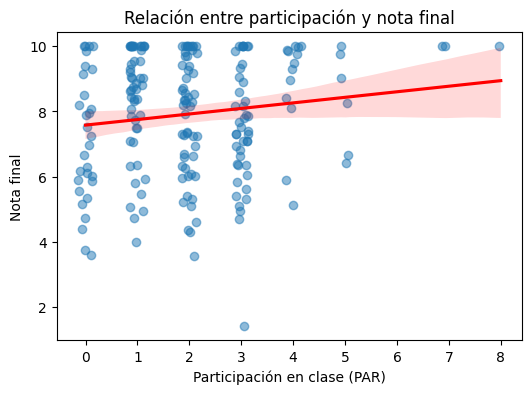

In [15]:
plt.figure(figsize=(6,4))
sns.regplot(x="PAR", y="NOTA", data=df,
            x_jitter=0.15,
            scatter_kws={"alpha": 0.5},
            line_kws={"color": "red"})
plt.title("Relación entre participación y nota final")
plt.xlabel("Participación en clase (PAR)")
plt.ylabel("Nota final")
plt.show()

Respuesta:

Modelo: regresión lineal simple, NOTA ~ PAR (n = 200).

Ecuación: NOTA = 7,580 + 0,170·PAR.

Interpretación: por cada participación adicional, la nota aumenta en promedio 0,17 puntos. El efecto no es significativo al 5% (p = 0,062) y el IC 95% incluye el cero.

Predicción: para un estudiante con 4 participaciones, la nota esperada es de [valor de la Celda 4], con un intervalo de predicción al 95% de [obs_ci_lower; obs_ci_upper].

Gráfico: la nube de puntos es muy dispersa y la recta de regresión es casi plana, lo que indica una relación positiva pero débil.

Limitaciones: R² = 0,017 (PAR explica solo el 1,7% de la variabilidad); los residuos se apartan de la normalidad (Jarque-Bera p = 0,001), probablemente por el techo de la escala de notas.

Conclusión: la participación en clase, por sí sola, no es un buen predictor del rendimiento académico final. Hay una tendencia positiva débil, no concluyente al 5%.

##Problema 2: Regresión Lineal Múltiple

Objetivo: Predecir la nota final a partir de múltiples factores académicos y personales.
- Intrucciones:
 1. Ajustá un modelo de regresión lineal múltiple donde:
○ Variable dependiente: NOTA
○ Variables independientes: CB, PAR, ASIS
 2. Reportá los coeficientes estimados.
 3. Interpretá qué variable tiene mayor peso en la predicción.
 4. Verificá supuestos básicos (linealidad, normalidad de residuos, multicolinealidad).
5. Usá el modelo para predecir la nota de un estudiante con:
○ CB = 6.8, PAR = 2, ASIS = 21


In [16]:
m2 = smf.ols("NOTA ~ CB + PAR + ASIS", data=df).fit()
print(m2.summary())

                            OLS Regression Results                            
Dep. Variable:                   NOTA   R-squared:                       0.064
Model:                            OLS   Adj. R-squared:                  0.049
Method:                 Least Squares   F-statistic:                     4.435
Date:                Thu, 12 Nov 2026   Prob (F-statistic):            0.00485
Time:                        03:08:47   Log-Likelihood:                -398.69
No. Observations:                 200   AIC:                             805.4
Df Residuals:                     196   BIC:                             818.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.0006      1.238      3.232      0.0

Peso de cada variable (coeficientes estandarizados)
Los coeficientes crudos no son comparables porque cada variable tiene otra escala. Estandarizamos:

In [17]:
cols = ["NOTA","CB","PAR","ASIS"]
dz = (df[cols] - df[cols].mean()) / df[cols].std()
m2z = smf.ols("NOTA ~ CB + PAR + ASIS", data=dz).fit()
print(m2z.params.drop("Intercept").sort_values(key=abs, ascending=False))

ASIS    0.168000
CB      0.152280
PAR     0.136949
dtype: float64


Supuestos

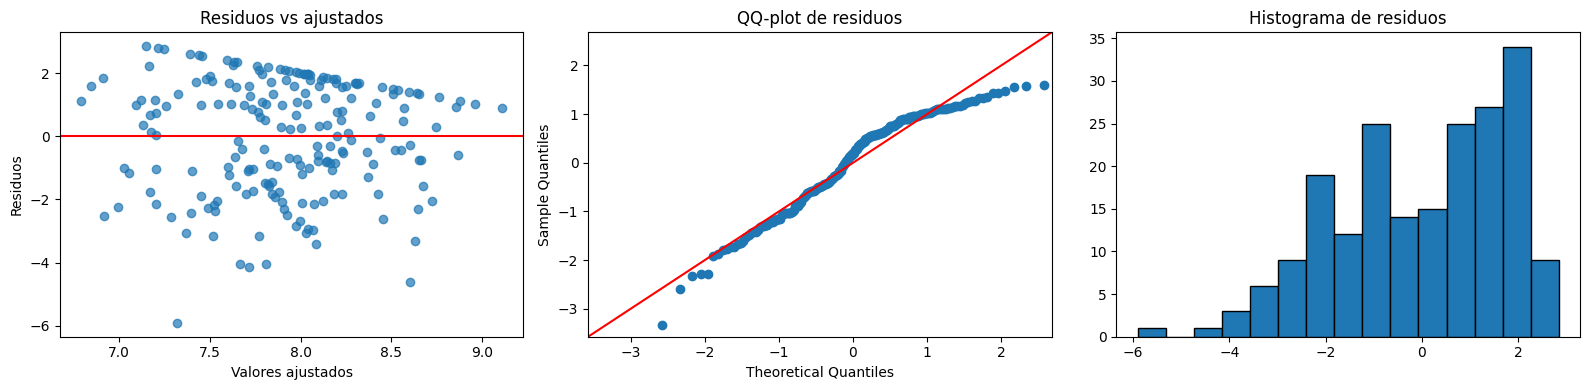

Shapiro-Wilk (normalidad): ShapiroResult(statistic=np.float64(0.9493777583518938), pvalue=np.float64(1.644248097579873e-06))
Breusch-Pagan (homocedasticidad): (np.float64(6.814774483545771), np.float64(0.0780418220102506))
  variable       VIF
0    const  1.000000
1       CB  1.011654
2      PAR  1.000907
3     ASIS  1.010769


In [18]:
res = m2.resid
fit = m2.fittedvalues

fig, ax = plt.subplots(1, 3, figsize=(16,4))

# Linealidad / homocedasticidad
ax[0].scatter(fit, res, alpha=.7)
ax[0].axhline(0, color="red")
ax[0].set_title("Residuos vs ajustados")
ax[0].set_xlabel("Valores ajustados"); ax[0].set_ylabel("Residuos")

# Normalidad
sm.qqplot(res, line="45", fit=True, ax=ax[1])
ax[1].set_title("QQ-plot de residuos")

ax[2].hist(res, bins=15, edgecolor="k")
ax[2].set_title("Histograma de residuos")
plt.tight_layout(); plt.show()

# Tests
print("Shapiro-Wilk (normalidad):", stats.shapiro(res))
print("Breusch-Pagan (homocedasticidad):", het_breuschpagan(res, m2.model.exog)[:2])

# Multicolinealidad (VIF)
X = sm.add_constant(df[["CB","PAR","ASIS"]])
vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
print(vif)

Predicción

In [19]:
nuevo = pd.DataFrame({"CB":[6.8], "PAR":[2], "ASIS":[21]})
print(f"Nota predicha: {m2.predict(nuevo)[0]:.2f}")
print(m2.get_prediction(nuevo).summary_frame(alpha=0.05))

Nota predicha: 8.29
       mean   mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  \
0  8.292058  0.178574       7.939884       8.644231      4.735896   

   obs_ci_upper  
0     11.848219  


Modelo

In [20]:
m3 = smf.logit("APROB ~ CB + PAR + MOT + ESP", data=df).fit()
print(m3.summary())

# Odds ratios con IC 95%
or_tab = pd.DataFrame({
    "coef": m3.params,
    "OR": np.exp(m3.params),
    "IC95_inf": np.exp(m3.conf_int()[0]),
    "IC95_sup": np.exp(m3.conf_int()[1]),
    "p_valor": m3.pvalues
}).round(4)
print(or_tab)

Optimization terminated successfully.
         Current function value: 0.236339
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                  APROB   No. Observations:                  200
Model:                          Logit   Df Residuals:                      195
Method:                           MLE   Df Model:                            4
Date:                Thu, 12 Nov 2026   Pseudo R-squ.:                 0.06821
Time:                        03:15:49   Log-Likelihood:                -47.268
converged:                       True   LL-Null:                       -50.728
Covariance Type:            nonrobust   LLR p-value:                    0.1402
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.7835      2.626     -1.060      0.289      -7.930       2.363
CB             0.6793      0.

Modelo: NOTA ~ CB + PAR + ASIS (n = 200). NOTA = 4,001 +

0,347·CB + 0,177·PAR + 0,075·ASIS.

Resultados: las tres variables tienen efecto positivo y significativo al 5% (CB p = 0,030; PAR p = 0,049; ASIS p = 0,017) y el modelo es globalmente significativo (F p = 0,005). Sin embargo, R² = 0,064 (ajustado 0,049): explica solo el 6,4% de la variabilidad. Respecto del Problema 1, el R² subió de 0,017 a 0,064 y PAR pasó a ser significativa, con un coeficiente casi igual.

Variable de mayor peso: según los coeficientes estandarizados, ASIS (0,168), seguida de CB (0,152) y PAR (0,137). Las diferencias son pequeñas: las tres aportan de forma similar.

Supuestos: no hay multicolinealidad (VIF ≈ 1) ni autocorrelación (DW ≈ 2); la homocedasticidad no se rechaza (Breusch-Pagan p = 0,078) y no se observa curvatura. La normalidad de residuos no se cumple (Shapiro p < 0,001), por el efecto techo en NOTA = 10. Con n = 200 los contrastes sobre los coeficientes son razonablemente robustos, pero los intervalos de predicción son poco confiables.

Predicción: para CB = 6,8, PAR = 2 y ASIS = 21, la nota esperada es 8,29 (IC 95% de la media: [7,94; 8,64]; intervalo de predicción individual: [4,74; 11,85], cuyo extremo superior excede la escala).

Conclusión: el modelo múltiple mejora al simple y confirma que asistir, tener buena base previa y participar se asocian con mejores notas, pero estos tres factores explican muy poco de la nota final. Sirven para describir tendencias, no para predecir la nota de un estudiante en particular.



##Problema 3: Regresión Logística

Objetivo: Predecir la probabilidad de aprobar la asignatura en función de variables personales y académicas.

 -Intrucciones:
 1. Ajustá un modelo de regresión logística donde:
○ Variable dependiente: APROB (1 = aprobó, 0 = no aprobó)
○ Variables independientes: CB, PAR, MOT, ESP
 2. Reportá los coeficientes logísticos y su significancia.
 3. Calculá la probabilidad de aprobar para un estudiante con:
○ CB = 6.0, PAR = 3, MOT = 3, ESP = 1
 4. Interpretá qué variable tiene mayor influencia en el resultado.

In [21]:
m3 = smf.logit("APROB ~ CB + PAR + MOT + ESP", data=df).fit()
print(m3.summary())

# Odds ratios con IC 95%
or_tab = pd.DataFrame({
    "coef": m3.params,
    "OR": np.exp(m3.params),
    "IC95_inf": np.exp(m3.conf_int()[0]),
    "IC95_sup": np.exp(m3.conf_int()[1]),
    "p_valor": m3.pvalues
}).round(4)
print(or_tab)

Optimization terminated successfully.
         Current function value: 0.236339
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                  APROB   No. Observations:                  200
Model:                          Logit   Df Residuals:                      195
Method:                           MLE   Df Model:                            4
Date:                Thu, 12 Nov 2026   Pseudo R-squ.:                 0.06821
Time:                        03:34:39   Log-Likelihood:                -47.268
converged:                       True   LL-Null:                       -50.728
Covariance Type:            nonrobust   LLR p-value:                    0.1402
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.7835      2.626     -1.060      0.289      -7.930       2.363
CB             0.6793      0.

Probabilidad

In [22]:
nuevo3 = pd.DataFrame({"CB":[6.0], "PAR":[3], "MOT":[3], "ESP":[1]})
p = m3.predict(nuevo3)[0]
print(f"Probabilidad de aprobar: {p:.3f} ({p*100:.1f}%)")

Probabilidad de aprobar: 0.962 (96.2%)


Influencia de las variables

In [23]:
cols = ["CB","PAR","MOT","ESP"]
dz3 = df.copy()
dz3[cols] = (df[cols] - df[cols].mean()) / df[cols].std()
m3z = smf.logit("APROB ~ CB + PAR + MOT + ESP", data=dz3).fit(disp=0)
print(m3z.params.drop("Intercept").sort_values(key=abs, ascending=False))

CB     0.547915
PAR    0.480506
ESP    0.327196
MOT    0.072225
dtype: float64


In [24]:
print(df["APROB"].value_counts())
print(df["APROB"].mean())

APROB
1    186
0     14
Name: count, dtype: int64
0.93


Modelo: regresión logística APROB ~ CB + PAR + MOT + ESP (n = 200; 186 aprobados y 14 no aprobados).

Coeficientes y significancia: ninguna variable es significativa al 5%. CB: coef. = 0,679, OR = 1,97, p = 0,086; PAR: 0,337, OR = 1,40, p = 0,159; ESP: 0,654, OR = 1,92, p = 0,270; MOT: 0,092, OR = 1,10, p = 0,795. Todos los IC 95% de los OR incluyen al 1. El modelo global tampoco es significativo (LLR p = 0,140; pseudo R² = 0,068).

Probabilidad estimada: para un estudiante con CB = 6,0, PAR = 3, MOT = 3 y ESP = 1, la probabilidad de aprobar es 96,2%.

Variable de mayor influencia: con las variables estandarizadas, CB (0,548) es la más influyente, seguida de PAR (0,481), ESP (0,327) y MOT (0,072). Un desvío estándar más de CB multiplica las chances de aprobar por 1,73. Sin embargo, el efecto de CB es significativo solo al 10% (p = 0,086).

Limitaciones: solo 14 de 200 estudiantes (7%) no aprobaron, lo que deja muy poca información para estimar cuatro coeficientes (unos 3,5 no aprobados por variable, por debajo de la regla práctica de 10). Esto explica los intervalos tan amplios y la falta de significancia

Conclusión: CB es la variable con mayor influencia sobre la probabilidad de aprobar, y la de PAR le sigue de cerca, pero con estos datos ninguna alcanza significancia al 5%. El modelo no permite predecir con confianza quién aprueba, principalmente por la escasez de desaprobados.

#Conclusiones generales

Participación (PAR) como predictor único: no es un buen predictor de la nota. El efecto es positivo (+0,17 puntos por participación), pero no significativo al 5% (p = 0,062) y explica solo el 1,7% de la variabilidad.
Modelo múltiple: al sumar CB y ASIS, las tres variables resultan significativas y el R² sube a 6,4%, pero sigue siendo muy bajo. ASIS, CB y PAR tienen un peso casi equivalente. Estos factores describen tendencias, no permiten predecir la nota individual (intervalo de predicción de más de 7 puntos).
Aprobación: ninguna variable predice significativamente la aprobación; CB y PAR muestran la asociación más fuerte, pero no concluyente, en parte porque casi todos los estudiantes aprueban.
Consistencia: en los tres problemas, CB, PAR y asistencia se asocian con mejor desempeño, pero explican una parte mínima del resultado. Es probable que haya otros factores no medidos (horas de estudio, dificultad del examen, etc.).
Limitaciones generales: efecto techo en NOTA = 10 (residuos no normales), muestra de 200 estudiantes y estudio observacional: las asociaciones no implican causalidad.
Aprobación: ninguna variable predice significativamente la aprobación. CB y PAR muestran la asociación más fuerte, pero no concluyente, en gran parte porque el 93% de los estudiantes aprobó (solo 14 desaprobados), lo que limita la capacidad del modelo.